In [66]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

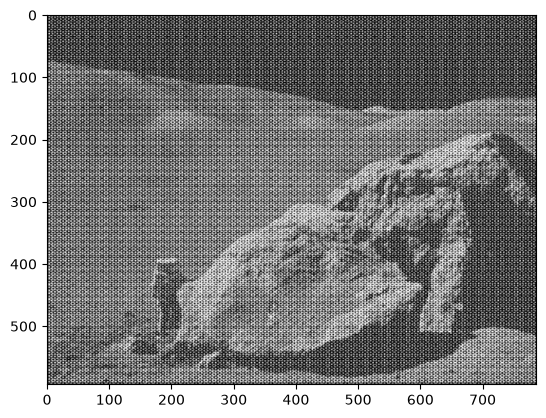

In [67]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

In [68]:
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

Высокочастотная фильтрация

In [69]:
def gaussian_high_pass_filter(shape, cutoff):
    rows, cols = shape
    center_row = rows // 2
    center_col = cols // 2
    
    u, v = np.meshgrid(np.arange(rows) - center_row, np.arange(cols) - center_col, indexing='ij')
    r2 = u**2 + v**2
    
    mask_low_pass = np.exp(-r2 / (2 * (cutoff**2)))
    mask_high_pass = 1 - mask_low_pass
    
    mask = np.zeros((rows, cols, 2), np.float32)
    mask[:, :, 0] = mask_high_pass
    mask[:, :, 1] = mask_high_pass
    return mask

Text(0.5, 1.0, 'Высокочастотная фильтрация')

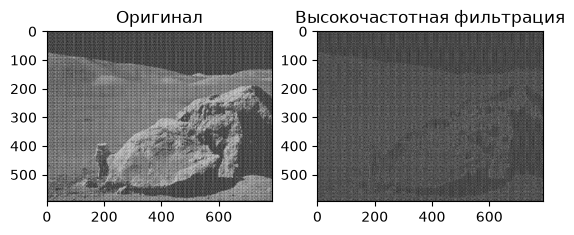

In [70]:
cutoff = 30
hp_mask = gaussian_high_pass_filter(img.shape, cutoff)

dft_shift_filtered = dft_shift * hp_mask
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back_hp = cv.idft(f_ishift)
img_back_hp = cv.magnitude(img_back_hp[:,:,0], img_back_hp[:,:,1])

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Оригинал')

plt.subplot(1,2,2)
plt.imshow(img_back_hp, cmap='gray')
plt.title('Высокочастотная фильтрация')

Вычисление свертки

In [71]:
kernel = np.ones((5, 5), np.float32) / 25.0

h, w = img.shape
kh, kw = kernel.shape
full_kernel = np.zeros((h, w), np.float32)
full_kernel[:kh, :kw] = kernel

full_kernel = np.roll(full_kernel, -kh//2, axis=0)
full_kernel = np.roll(full_kernel, -kw//2, axis=1)

In [72]:
dft_kernel = cv.dft(np.float32(full_kernel), flags=cv.DFT_COMPLEX_OUTPUT)

dft_conv = np.zeros_like(dft)
dft_conv[:,:,0] = dft[:,:,0] * dft_kernel[:,:,0] - dft[:,:,1] * dft_kernel[:,:,1]
dft_conv[:,:,1] = dft[:,:,0] * dft_kernel[:,:,1] + dft[:,:,1] * dft_kernel[:,:,0]

Text(0.5, 1.0, 'Свертка')

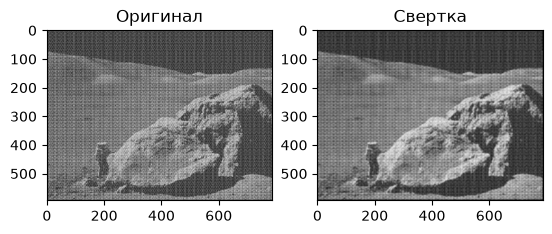

In [73]:
img_conv_back = cv.idft(dft_conv)
img_conv_back = cv.magnitude(img_conv_back[:,:,0], img_conv_back[:,:,1])

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Оригинал')

plt.subplot(1,2,2)
plt.imshow(img_conv_back, cmap='gray')
plt.title('Свертка')

Удаление периодического шума

In [74]:
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

Text(0.5, 1.0, 'Фильтр')

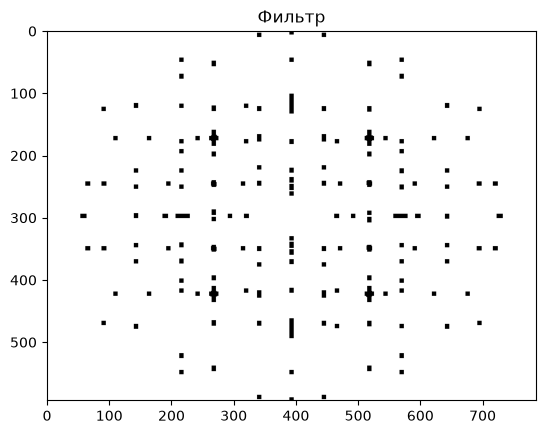

In [75]:
mask = np.ones(dft_shift.shape, np.uint8)
centerX, centerY = (img.shape[0] // 2, img.shape[1] // 2)

T = 250
R = 30
dots = np.argwhere(magnitude_spectrum > T)
for x,y in dots:
    if (x - centerX)**2 + (y - centerY)**2 > R**2:
        mask[max(0,x-3):x+4, max(0, y-3):y+4, :] = 0

plt.imshow(mask[:,:,0], cmap='gray')
plt.title('Фильтр')

In [76]:
dft_shift_n = dft_shift * mask
f_ishift_n = np.fft.ifftshift(dft_shift_n)
img_back_n = cv.idft(f_ishift_n)
img_back_n = cv.magnitude(img_back_n[:,:,0], img_back_n[:,:,1])

Text(0.5, 1.0, 'Без периодического шума')

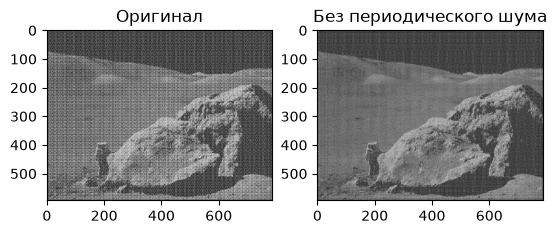

In [77]:
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Оригинал')

plt.subplot(1,2,2)
plt.imshow(img_back_n, cmap='gray')
plt.title('Без периодического шума')